### Load libraries

In [1]:
# systemic libraries
import os 
import warnings
warnings.simplefilter(action='ignore', category=FutureWarning)
import sys

# single-cell and data-wrangling 
import scanpy as sc 
import pandas as pd 
import numpy as np 
import anndata as ad
import leidenalg
import scanpy.external as sce

# visualization
import igraph as ig
import matplotlib.pyplot as plt
import seaborn as sns
import matplotlib.cm as cm
from matplotlib.colors import LinearSegmentedColormap

<i><b> Set the home directory </b></i>

In [2]:
env_path = "../.env"
# call paths from .env
if os.path.exists(env_path):
    with open(env_path) as f:
        os.environ.update(
            line.strip().split("=", 1) for line in f
            if line.strip() and not line.startswith("#")
        )
        
plots_dir = os.getenv("PLOTS_DIR")
processed_adata_dir = os.getenv("PROCESSED_ANNDATA_DIR")
src_dir = os.getenv("SRC_DIR")

### Load the data

In [3]:
# Load the individual datasets to extract sample_id information
adata = sc.read_h5ad(processed_adata_dir + "Adata_clustered.h5ad")

### Subclustering

In [4]:
# Define the species column 
adata.obs['species'] = adata.obs['dataset_of_origin'].map({
    'Polioudakis': 'human_ncx',
    'Trevino': 'human_ncx', 
    'Linnarsson': 'mouse_dg', 
    'Zylka': 'mouse_ncx', 
    'Ruan': 'mouse_ncx', 
    'Zhong': 'human_dg'
})

In [5]:
# Subset to G1 RG per species
## Human Ncx
adata_RG_hs_ncx = adata[(adata.obs['species'] == 'human_ncx') & (adata.obs['X_leiden_harmony'] == 'G1 RG')].copy()
## Mouse Ncx 
adata_RG_mm_ncx = adata[(adata.obs['species'] == 'mouse_ncx') & (adata.obs['X_leiden_harmony'] == 'G1 RG')].copy()
## Mouse DG
adata_RG_mm_dg = adata[(adata.obs['species'] == 'mouse_dg') & (adata.obs['X_leiden_harmony'] == 'G1 RG')].copy()
## Human DG
adata_RG_hs_dg = adata[(adata.obs['species'] == 'human_dg') & (adata.obs['X_leiden_harmony'] == 'G1 RG')].copy()

In [6]:
# Print the number of cells 
print("Number of cells in the human Ncx RG:", adata_RG_hs_ncx.shape[0])
print("Number of cells in the mouse DG RG:", adata_RG_mm_dg.shape[0])
print("Number of cells in the mouse Ncx RG:", adata_RG_mm_ncx.shape[0])
print("Number of cells in the human DG RG:", adata_RG_hs_dg.shape[0])

Number of cells in the human Ncx RG: 5266
Number of cells in the mouse DG RG: 2103
Number of cells in the mouse Ncx RG: 1535
Number of cells in the human DG RG: 1293


In [7]:
script_path = src_dir + 'round_to_nearest.py'
%run -i $script_path
adatas = {
    "human_neocortex" : adata_RG_hs_ncx, 
    "mouse_dentate_gyrus": adata_RG_mm_dg, 
    "mouse_neocortex": adata_RG_mm_ncx,
    "human_dentate_gyrus": adata_RG_hs_dg
}

for name, ad in adatas.items():
    ad_copy = ad.copy()
    cell_number = ad_copy.shape[0]
    original_number = cell_number*0.01
    rounded_number = round_to_nearest_number(original_number, basis = 10)
    print(f"For {name} dataset: | original number is: {original_number} | rounded number is: {rounded_number}")

For human_neocortex dataset: | original number is: 52.660000000000004 | rounded number is: 50
For mouse_dentate_gyrus dataset: | original number is: 21.03 | rounded number is: 20
For mouse_neocortex dataset: | original number is: 15.35 | rounded number is: 20
For human_dentate_gyrus dataset: | original number is: 12.93 | rounded number is: 10


In [8]:
# Re-compute nearest neighbors
sc.pp.neighbors(adata_RG_hs_ncx, use_rep='X_pca_harmony', n_pcs=30, n_neighbors=50, random_state = 111)
sc.pp.neighbors(adata_RG_mm_dg, use_rep='X_pca_harmony', n_pcs=30, n_neighbors=20, random_state = 111)
sc.pp.neighbors(adata_RG_mm_ncx, use_rep='X_pca_harmony', n_pcs=30, n_neighbors=20, random_state = 111)
sc.pp.neighbors(adata_RG_hs_dg, use_rep='X_pca_harmony', n_pcs=30, n_neighbors=10, random_state = 111)

2026-05-19 20:06:23.833689: I tensorflow/core/util/port.cc:113] oneDNN custom operations are on. You may see slightly different numerical results due to floating-point round-off errors from different computation orders. To turn them off, set the environment variable `TF_ENABLE_ONEDNN_OPTS=0`.
2026-05-19 20:06:24.603553: E external/local_xla/xla/stream_executor/cuda/cuda_dnn.cc:9261] Unable to register cuDNN factory: Attempting to register factory for plugin cuDNN when one has already been registered
2026-05-19 20:06:24.603587: E external/local_xla/xla/stream_executor/cuda/cuda_fft.cc:607] Unable to register cuFFT factory: Attempting to register factory for plugin cuFFT when one has already been registered
2026-05-19 20:06:24.743317: E external/local_xla/xla/stream_executor/cuda/cuda_blas.cc:1515] Unable to register cuBLAS factory: Attempting to register factory for plugin cuBLAS when one has already been registered
2026-05-19 20:06:25.010321: I tensorflow/core/platform/cpu_feature_guar

Number of cells per subcluster: leiden_subclustered_G1 RG
RG 1    2248
RG 2    2204
RG 3     814
Name: count, dtype: int64


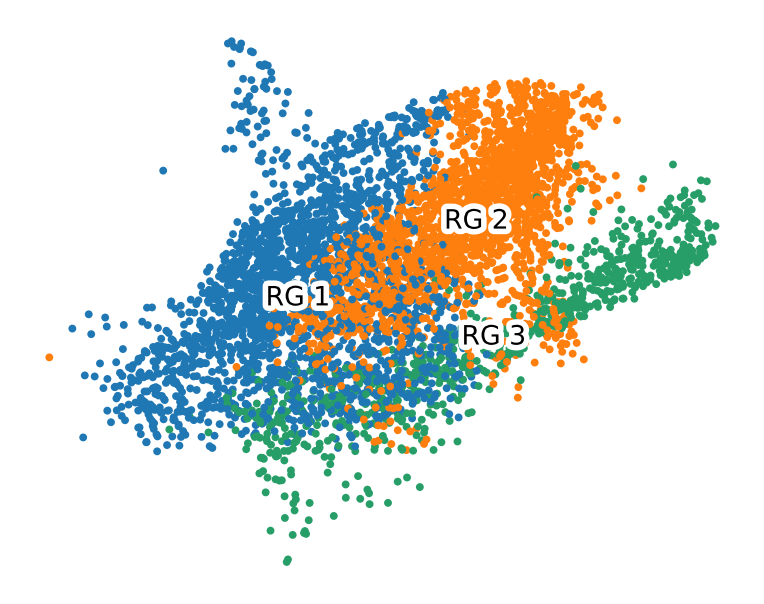

/tmp/ipykernel_310510/3976305371.py:26: UserWarning: This figure includes Axes that are not compatible with tight_layout, so results might be incorrect.
  plt.tight_layout()


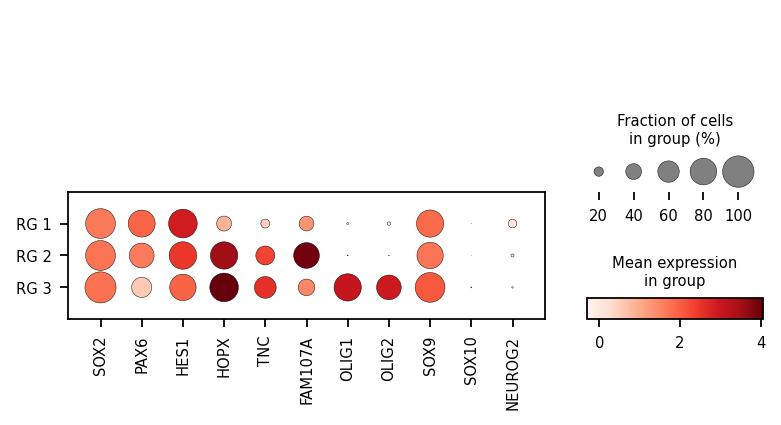

In [9]:
# Subcluster human Ncx 
clusters = ['G1 RG']
for cluster in clusters:
    sc.tl.leiden(adata_RG_hs_ncx, resolution=0.20, key_added=f'leiden_subclustered_{cluster}', restrict_to=('X_leiden_harmony', [cluster]),  random_state=111)

# Rename clusters
reannot = ['RG 1', 'RG 2', 'RG 3']
adata_RG_hs_ncx.rename_categories('leiden_subclustered_G1 RG', reannot)

# Print number of cells per each subcluster
print("Number of cells per subcluster:", adata_RG_hs_ncx.obs['leiden_subclustered_G1 RG'].value_counts())

# Plot clusters 
sc.set_figure_params(figsize=(5, 4))
sc.pl.umap(adata_RG_hs_ncx, color=["leiden_subclustered_G1 RG"],frameon=False, show = False, legend_fontsize=12, size =50,
           legend_loc = 'on data', legend_fontweight=4, ncols = 1, legend_fontoutline = 5, title = '')
plt.tight_layout()
plt.savefig(plots_dir + 'clustering/UMAP_RG_human_ncx_subsets.svg', dpi = 300, bbox_inches = 'tight')
plt.show()

# Plot the dotplot
markers = ['SOX2', 'PAX6', 'HES1', 'HOPX', 'TNC', 'FAM107A', 'OLIG1', 'OLIG2', 'SOX9', 'SOX10', 'NEUROG2']
sc.set_figure_params(fontsize=8)
sc.pl.dotplot(adata_RG_hs_ncx, markers, groupby ='leiden_subclustered_G1 RG', 
              mean_only_expressed = False, show = False, cmap = 'Reds')
plt.tight_layout()
plt.savefig(plots_dir + 'clustering/Dotplot_RG_human_ncx_subsets.svg', dpi = 300, bbox_inches = 'tight')
plt.show()

Number of cells per subcluster: leiden_subclustered_G1 RG
G1 RG,0    1057
G1 RG,1     959
G1 RG,2      87
Name: count, dtype: int64


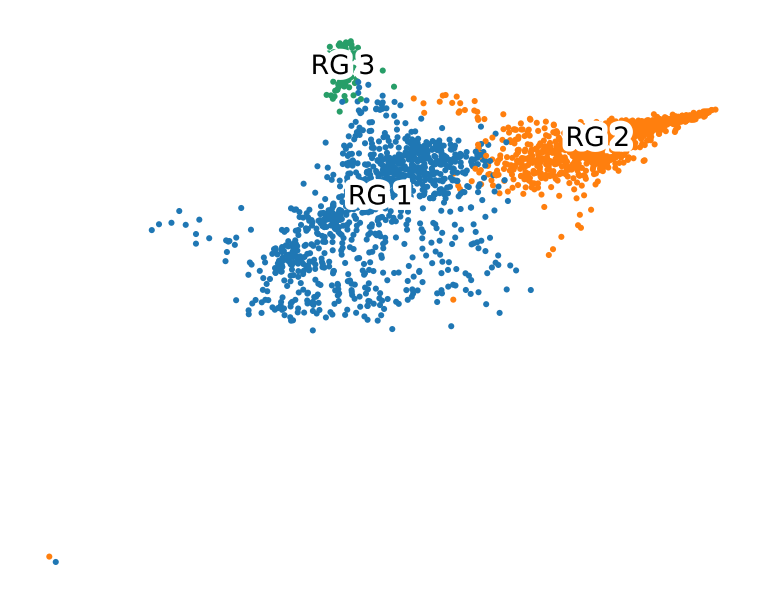

/tmp/ipykernel_310510/196718498.py:28: UserWarning: This figure includes Axes that are not compatible with tight_layout, so results might be incorrect.
  plt.tight_layout()


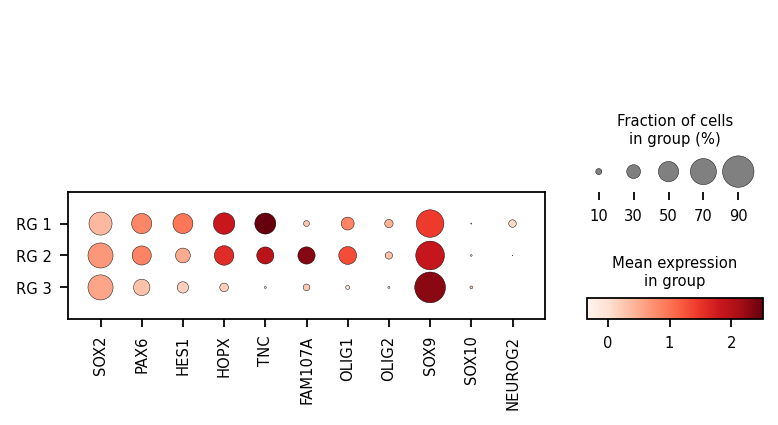

In [10]:
# Subcluster Mouse DG 
clusters = ['G1 RG']
for cluster in clusters:
    sc.tl.leiden(adata_RG_mm_dg, resolution=0.10, key_added=f'leiden_subclustered_{cluster}', restrict_to=('X_leiden_harmony', [cluster]),  random_state=111)


# Print number of cells per each subcluster
print("Number of cells per subcluster:", adata_RG_mm_dg.obs['leiden_subclustered_G1 RG'].value_counts())

# Rename clusters
reannot = ['RG 1', 'RG 2', 'RG 3']
adata_RG_mm_dg.rename_categories('leiden_subclustered_G1 RG', reannot)

# Plot clusters 
sc.set_figure_params(figsize=(5, 4))
sc.pl.umap(adata_RG_mm_dg, color=["leiden_subclustered_G1 RG"],frameon=False, show = False, legend_fontsize=12, size =30,
           legend_loc = 'on data', legend_fontweight=4, ncols = 1, legend_fontoutline = 5, title = '')
plt.tight_layout()
plt.savefig(plots_dir + 'clustering/UMAP_RG_mouse_dg_subsets.svg', dpi = 300, bbox_inches = 'tight')
plt.show()

# Plot the dotplot
markers = ['SOX2', 'PAX6', 'HES1', 'HOPX', 'TNC', 'FAM107A', 'OLIG1', 'OLIG2', 'SOX9', 'SOX10', 'NEUROG2']
sc.set_figure_params(fontsize=8)
sc.pl.dotplot(adata_RG_mm_dg, markers, groupby ='leiden_subclustered_G1 RG', 
              mean_only_expressed = False, show = False, cmap = 'Reds')

plt.tight_layout()
plt.savefig(plots_dir + 'clustering/Dotplot_RG_mouse_dg_subsets.svg', dpi = 300, bbox_inches = 'tight')
plt.show()

Number of cells per subcluster: leiden_subclustered_G1 RG
G1 RG,0    1535
Name: count, dtype: int64


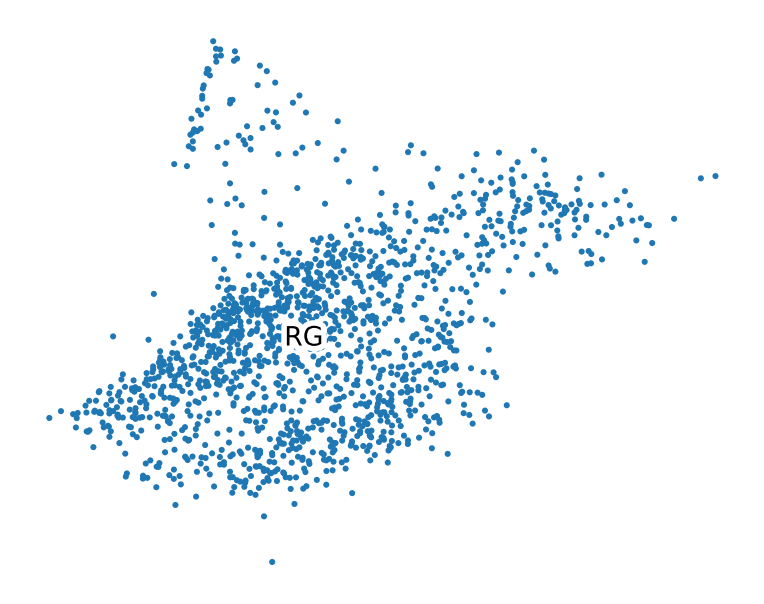

/tmp/ipykernel_310510/2122680813.py:27: UserWarning: This figure includes Axes that are not compatible with tight_layout, so results might be incorrect.
  plt.tight_layout()


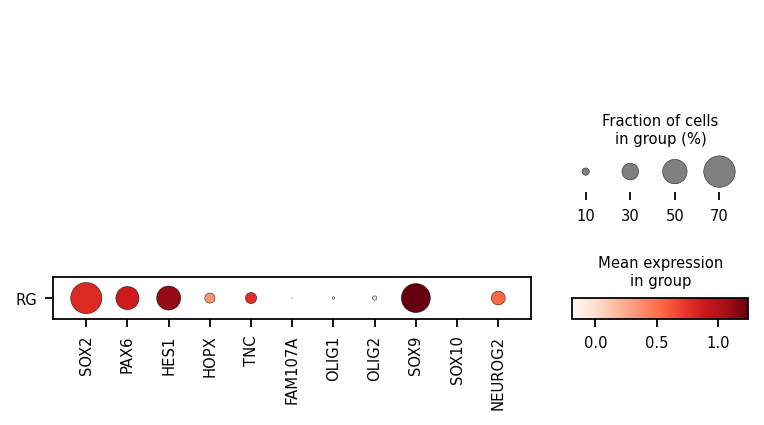

In [11]:
# Subcluster mouse Ncx 
clusters = ['G1 RG']
for cluster in clusters:
    sc.tl.leiden(adata_RG_mm_ncx, resolution=0.10, key_added=f'leiden_subclustered_{cluster}', restrict_to=('X_leiden_harmony', [cluster]),  random_state=111)

# Print number of cells per each subcluster
print("Number of cells per subcluster:", adata_RG_mm_ncx.obs['leiden_subclustered_G1 RG'].value_counts())

# Rename clusters
reannot = ['RG']
adata_RG_mm_ncx.rename_categories('leiden_subclustered_G1 RG', reannot)

# Plot clusters 
sc.set_figure_params(figsize=(5, 4))
sc.pl.umap(adata_RG_mm_ncx, color=["leiden_subclustered_G1 RG"],frameon=False, show = False, legend_fontsize=12, size =30,
           legend_loc = 'on data', legend_fontweight=4, ncols = 1, legend_fontoutline = 5, title = '')
plt.tight_layout()
plt.savefig(plots_dir + 'clustering/UMAP_RG_mouse_ncx_subsets.svg', dpi = 300, bbox_inches = 'tight')
plt.show()


# Plot the dotplot
markers = ['SOX2', 'PAX6', 'HES1', 'HOPX', 'TNC', 'FAM107A', 'OLIG1', 'OLIG2', 'SOX9', 'SOX10', 'NEUROG2']
sc.set_figure_params(fontsize=8)
sc.pl.dotplot(adata_RG_mm_ncx, markers, groupby ='leiden_subclustered_G1 RG', 
              mean_only_expressed = False, show = False, cmap = 'Reds')
plt.tight_layout()
plt.savefig(plots_dir + 'clustering/Dotplot_RG_mouse_ncx_subsets.svg', dpi = 300, bbox_inches = 'tight')
plt.show()

Number of cells per subcluster: leiden_subclustered_G1 RG
G1 RG,0    707
G1 RG,1    452
G1 RG,2    134
Name: count, dtype: int64


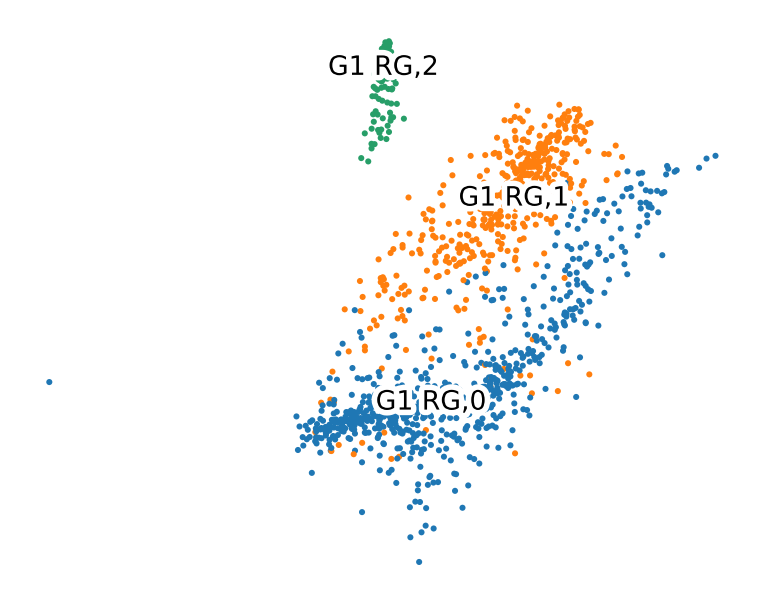

/tmp/ipykernel_310510/1642526186.py:27: UserWarning: This figure includes Axes that are not compatible with tight_layout, so results might be incorrect.
  plt.tight_layout()


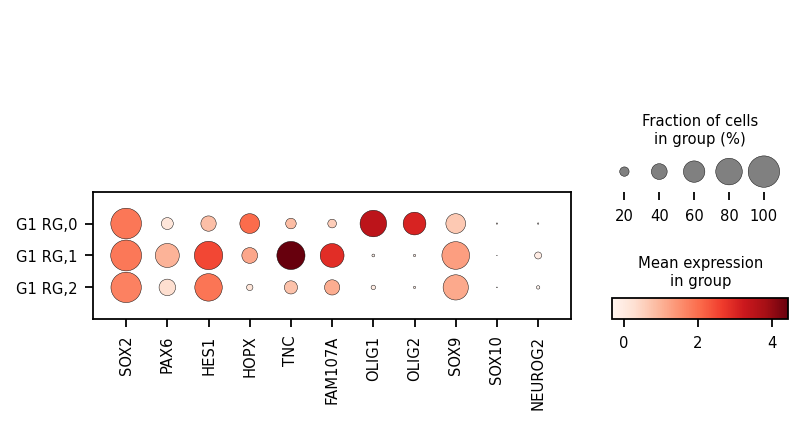

In [12]:
# Subcluster human DG 
clusters = ['G1 RG']
for cluster in clusters:
    sc.tl.leiden(adata_RG_hs_dg, resolution=0.10, key_added=f'leiden_subclustered_{cluster}', restrict_to=('X_leiden_harmony', [cluster]),  random_state=111)

# Print number of cells per each subcluster
print("Number of cells per subcluster:", adata_RG_hs_dg.obs['leiden_subclustered_G1 RG'].value_counts())

# Rename clusters
#reannot = ['RG']
#adata_RG_mm_ncx.rename_categories('leiden_subclustered_G1 RG', reannot)

# Plot clusters 
sc.set_figure_params(figsize=(5, 4))
sc.pl.umap(adata_RG_hs_dg, color=["leiden_subclustered_G1 RG"],frameon=False, show = False, legend_fontsize=12, size =30,
           legend_loc = 'on data', legend_fontweight=4, ncols = 1, legend_fontoutline = 5, title = '')
plt.tight_layout()
plt.savefig(plots_dir + 'clustering/UMAP_RG_hs_dg_subsets.svg', dpi = 300, bbox_inches = 'tight')
plt.show()


# Plot the dotplot
markers = ['SOX2', 'PAX6', 'HES1', 'HOPX', 'TNC', 'FAM107A', 'OLIG1', 'OLIG2', 'SOX9', 'SOX10', 'NEUROG2']
sc.set_figure_params(fontsize=8)
sc.pl.dotplot(adata_RG_hs_dg, markers, groupby ='leiden_subclustered_G1 RG', 
              mean_only_expressed = False, show = False, cmap = 'Reds')
plt.tight_layout()
plt.savefig(plots_dir + 'clustering/Dotplot_RG_hs_dg_subsets.svg', dpi = 300, bbox_inches = 'tight')
plt.show()

### Map subclusters to the dataset

In [13]:
# Define the empty .obs category
adata.obs['leiden_subclustered_G1_RG_ss'] = ""
# Map the human ncx RG to the full dataset
adata.obs.loc[adata_RG_hs_ncx.obs_names, 'leiden_subclustered_G1_RG_ss'] = 'human_ncx_' + adata_RG_hs_ncx.obs['leiden_subclustered_G1 RG'].astype(str)
# Map the mouse DG RG to the full dataset
adata.obs.loc[adata_RG_mm_dg.obs_names, 'leiden_subclustered_G1_RG_ss'] = 'mouse_dg_' + adata_RG_mm_dg.obs['leiden_subclustered_G1 RG'].astype(str)
# Map the mouse DG RG to the full dataset
adata.obs.loc[adata_RG_mm_ncx.obs_names, 'leiden_subclustered_G1_RG_ss'] = 'mouse_ncx_' + adata_RG_mm_ncx.obs['leiden_subclustered_G1 RG'].astype(str)
# Map the human DG RG to the full dataset
adata.obs.loc[adata_RG_hs_dg.obs_names, 'leiden_subclustered_G1_RG_ss'] = 'human_dg_' + adata_RG_hs_dg.obs['leiden_subclustered_G1 RG'].astype(str)

### Save the data

In [14]:
# Save the anndata
adata.write_h5ad(processed_adata_dir + 'Adata_subclustered.h5ad')